# Problem 14 — 3D Ray Tracing: **Stage 3 (V3) – Whole-Mesh AABB Slab Rejection**
*Student 2 — Ray Intersections & AABB (Slides 4–6)*

**What V3 adds to V2.** V2 = indexed mesh + Möller–Trumbore (tests every triangle for every ray).
V3 first computes **one** tight axis-aligned box around the whole mesh (done once, O(V)).
For every ray we run the Kay–Kajiya slab test (6 subtractions + 6 multiplications by 1/d, O(1)).
If the ray misses the box → return "no hit" immediately, **0 triangle tests**.
If it hits the box → fall back to the V2 scan over all N triangles.

| | V2 | V3 |
|---|---|---|
| Rays that miss the object | N triangle tests | **1 slab test, 0 triangle tests** |
| Rays that hit the box | N triangle tests | 1 slab test + N triangle tests |
| Worst case per ray | Θ(N) | Θ(N) (still brute force inside the box) |

The notebook is organised as: (1) building blocks, (2) unit tests = the hand-worked Q2/Q3 from the sheet,
(3) differential correctness test (V3 ≡ V2), (4) counters + scaling, (5) shaded 128×128 render.

In [2]:
import numpy as np, time
import matplotlib.pyplot as plt

## 1. Scene generation (icosphere + ground plane + small-sphere cluster)
*(Same generator as Student 1's mesh code — included so this notebook runs standalone.)*

In [3]:
def icosphere(center, radius, subdiv):
    t = (1 + 5 ** 0.5) / 2
    v = [(-1, t, 0), (1, t, 0), (-1, -t, 0), (1, -t, 0), (0, -1, t), (0, 1, t),
         (0, -1, -t), (0, 1, -t), (t, 0, -1), (t, 0, 1), (-t, 0, -1), (-t, 0, 1)]
    f = [(0, 11, 5), (0, 5, 1), (0, 1, 7), (0, 7, 10), (0, 10, 11), (1, 5, 9), (5, 11, 4),
         (11, 10, 2), (10, 7, 6), (7, 1, 8), (3, 9, 4), (3, 4, 2), (3, 2, 6), (3, 6, 8),
         (3, 8, 9), (4, 9, 5), (2, 4, 11), (6, 2, 10), (8, 6, 7), (9, 8, 1)]
    v = [np.array(p, float) / np.linalg.norm(p) for p in v]
    for _ in range(subdiv):
        cache, nf = {}, []
        def mid(a, b):
            k = (min(a, b), max(a, b))
            if k not in cache:
                m = (v[a] + v[b]) / 2
                v.append(m / np.linalg.norm(m))
                cache[k] = len(v) - 1
            return cache[k]
        for a, b, c in f:
            ab, bc, ca = mid(a, b), mid(b, c), mid(c, a)
            nf += [(a, ab, ca), (b, bc, ab), (c, ca, bc), (ab, bc, ca)]
        f = nf
    return np.array(v) * radius + np.asarray(center, float), np.array(f)

def merge(meshes):
    V, F, off = [], [], 0
    for v, f in meshes:
        V.append(v); F.append(f + off); off += len(v)
    return np.vstack(V), np.vstack(F)

def ground_plane(y, half, n=2):
    xs = np.linspace(-half, half, n + 1)
    V = np.array([(x, y, z) for z in xs for x in xs])
    F = []
    for j in range(n):
        for i in range(n):
            a = j * (n + 1) + i; b = a + 1; c = a + n + 1; d = c + 1
            F += [(a, c, b), (b, c, d)]
    return V, np.array(F)

def build_scene(n_target=1000, seed=0):
    """big icosphere + ground plane + cluster of small detailed spheres (~n_target triangles)"""
    rng = np.random.default_rng(seed)
    sub = 1 if n_target < 400 else (2 if n_target < 3000 else 3)     # 80 / 320 / 1280 tris
    parts = [icosphere((0, 0, 0), 1.0, sub), ground_plane(-1.0, 4.0, 2)]
    total = sum(len(f) for _, f in parts)
    while total < n_target:
        c = rng.uniform(-1.5, 1.5, 3); c[1] = rng.uniform(-0.9, 0.5)
        parts.append(icosphere(c, 0.12, 1)); total += 80             # +80 tris each
    return merge(parts)

## 2. Möller–Trumbore (Stage 2 kernel that V3 reuses)
Solve $o + t\,d = v_0 + u\,e_1 + v\,e_2$ with Cramer's rule:
$P = d\times e_2,\; Q = T\times e_1,\; \det = P\cdot e_1,\;
t = \frac{Q\cdot e_2}{\det},\; u = \frac{P\cdot T}{\det},\; v = \frac{Q\cdot d}{\det}$ with $T=o-v_0$.
Hit iff $u\ge0,\ v\ge0,\ u+v\le1,\ t>0$. $|\det|\approx0$ → ray parallel to the triangle plane.
This version is vectorised over all triangles for one ray.

In [4]:
# ------------------------------------------------------------------
EPS = 1e-12
def moller_trumbore_all(o, d, V, F, ids=None):
    """Return (tri_id, t) of closest hit with t>0, or (-1, inf)."""
    v0, v1, v2 = V[F[:, 0]], V[F[:, 1]], V[F[:, 2]]
    e1, e2 = v1 - v0, v2 - v0
    P = np.cross(d, e2)                      # P = d x e2
    det = np.einsum('ij,ij->i', P, e1)       # det = P . e1
    ok = np.abs(det) > EPS                   # det≈0 -> ray parallel to plane
    inv = np.where(ok, 1.0 / np.where(ok, det, 1.0), 0.0)
    T = o - v0
    u = np.einsum('ij,ij->i', P, T) * inv
    Q = np.cross(T, e1)                      # Q = T x e1
    v = (Q @ d) * inv
    t = np.einsum('ij,ij->i', Q, e2) * inv
    hit = ok & (u >= 0) & (v >= 0) & (u + v <= 1) & (t > 1e-9)
    if not hit.any():
        return -1, np.inf
    tt = np.where(hit, t, np.inf)
    i = int(np.argmin(tt))
    return i, float(tt[i])

## 3. Stage 3 — whole-mesh AABB + slab test
For each axis $k$: $t_{0,k},t_{1,k}$ = the two times the ray crosses the planes $x_k=b_{min,k}$ and $x_k=b_{max,k}$
(swap them if $d_k<0$). Then  
$t_{enter}=\max(0,t_{0,x},t_{0,y},t_{0,z}),\quad t_{exit}=\min(t_{1,x},t_{1,y},t_{1,z})$ and the ray hits the box iff $t_{enter}\le t_{exit}$.

Edge case handled explicitly: if $d_k=0$ the ray is parallel to that slab → it is either inside it forever
(interval $(-\infty,\infty)$, skip) or outside it forever (miss). This also avoids the `0/0 = NaN` problem when the origin lies exactly on a box face.

In [5]:
# ------------------------------------------------------------------
def mesh_aabb(V, F=None):
    if F is not None: V = V[np.unique(F)]     # only vertices actually used by faces
    return V.min(axis=0), V.max(axis=0)       # tightest box, O(V), done ONCE

def ray_aabb(o, d, bmin, bmax):
    """Slab test. Returns (hit, t_enter, t_exit). Handles d_i = 0 explicitly."""
    t_enter, t_exit = 0.0, np.inf             # ray starts at t = 0
    for k in range(3):
        if d[k] == 0.0:                       # parallel to this slab
            if o[k] < bmin[k] or o[k] > bmax[k]:
                return False, np.inf, -np.inf # outside slab forever -> miss
            continue                          # inside slab forever -> (-inf, inf)
        inv = 1.0 / d[k]
        t0, t1 = (bmin[k] - o[k]) * inv, (bmax[k] - o[k]) * inv
        if t0 > t1:
            t0, t1 = t1, t0                   # negative direction: swap
        t_enter, t_exit = max(t_enter, t0), min(t_exit, t1)
        if t_enter > t_exit:
            return False, t_enter, t_exit     # early out
    return True, t_enter, t_exit

class Counters:
    def __init__(self): self.slab = 0; self.tri = 0

def trace_v3(o, d, V, F, box, cnt=None):
    """V3 = AABB reject, else brute-force Möller–Trumbore over all N triangles."""
    if cnt: cnt.slab += 1
    hit, _, _ = ray_aabb(o, d, *box)
    if not hit:
        return -1, np.inf                     # O(1) rejection
    if cnt: cnt.tri += len(F)
    return moller_trumbore_all(o, d, V, F)

def trace_v2(o, d, V, F, cnt=None):           # baseline: no box
    if cnt: cnt.tri += len(F)
    return moller_trumbore_all(o, d, V, F)

In [6]:
def camera_rays(w, h, eye, look, fov=40.0):
    eye, look = np.asarray(eye, float), np.asarray(look, float)
    f = look - eye; f /= np.linalg.norm(f)
    r = np.cross(f, [0, 1, 0]); r /= np.linalg.norm(r)
    u = np.cross(r, f)
    s = np.tan(np.radians(fov) / 2)
    xs = (np.arange(w) + .5) / w * 2 - 1
    ys = 1 - (np.arange(h) + .5) / h * 2
    X, Y = np.meshgrid(xs * s * w / h, ys * s)
    D = f + X[..., None] * r + Y[..., None] * u
    D /= np.linalg.norm(D, axis=-1, keepdims=True)
    return eye, D.reshape(-1, 3)

## 4. Unit tests = the hand-worked questions (Q2 and Q3)

In [7]:
# ---- Q2: Möller–Trumbore by hand -> code must give t=3, u=v=0.25, hit (1,1,0)
v0, v1, v2 = np.array([0,0,0.]), np.array([4,0,0.]), np.array([0,4,0.])
o, d = np.array([1,1,3.]), np.array([0,0,-1.])
e1, e2, T = v1-v0, v2-v0, o-v0
P, Q = np.cross(d, e2), np.cross(T, e1)
det = P @ e1
t, u, v = (Q @ e2)/det, (P @ T)/det, (Q @ d)/det
print("e1",e1,"e2",e2,"T",T,"| P",P,"Q",Q,"det",det)
print("t,u,v =",t,u,v,"| hit point", o+t*d)
assert (t,u,v)==(3.0,0.25,0.25) and np.allclose(o+t*d,[1,1,0])
# the vectorised kernel must agree
Vq = np.array([v0,v1,v2]); Fq = np.array([[0,1,2]])
print("kernel ->", moller_trumbore_all(o, d, Vq, Fq))

# ---- Q3: slab test by hand
bmin, bmax = np.zeros(3), np.full(3, 2.0)
o3 = np.array([-1,1,1.])
for name, dd in [("A", [1,.2,.2]), ("B", [1,2,0])]:
    print(name, ray_aabb(o3, np.array(dd, float), bmin, bmax))
assert ray_aabb(o3, np.array([1,.2,.2]), bmin, bmax) == (True, 1.0, 3.0)
assert ray_aabb(o3, np.array([1,2,0.]),  bmin, bmax)[0] is False
print("Q2 and Q3 reproduced by the code ✔")

e1 [4. 0. 0.] e2 [0. 4. 0.] T [1. 1. 3.] | P [ 4. -0.  0.] Q [ 0. 12. -4.] det 16.0
t,u,v = 3.0 0.25 0.25 | hit point [1. 1. 0.]
kernel -> (0, 3.0)
A (True, np.float64(1.0), np.float64(3.0))
B (False, np.float64(1.0), np.float64(0.5))
Q2 and Q3 reproduced by the code ✔


## 5. Experiment 1 — differential correctness: V3 must equal V2 on every ray
N ≈ 1,000 triangles, 2,000 camera rays (50×40 image). Same hit triangle ID and |Δt| < 1e-6.

In [8]:
V, F = build_scene(1000)
box = mesh_aabb(V, F)
print("vertices:", len(V), " triangles N =", len(F), " box:", box[0], box[1])

eye, D = camera_rays(50, 40, (0, 1.5, 9), (0, 0, 0), fov=50)
print("rays:", len(D))
c2, c3 = Counters(), Counters()
r2 = [trace_v2(eye, d, V, F, c2)      for d in D]
r3 = [trace_v3(eye, d, V, F, box, c3) for d in D]

for (i2, t2), (i3, t3) in zip(r2, r3):
    assert i2 == i3, (i2, i3)
    if np.isfinite(t2): assert abs(t2 - t3) < 1e-6
hits = sum(i >= 0 for i, _ in r2)
rejected = len(D) - c3.tri // len(F)
print(f"All {len(D)} rays identical ✔   ({hits} hit the mesh, {len(D)-hits} background)")
print(f"V2: {c2.tri/len(D):8.1f} triangle tests / ray")
print(f"V3: {c3.slab/len(D):8.1f} slab test  / ray,  {c3.tri/len(D):8.1f} triangle tests / ray")
print(f"{rejected} of {len(D)} rays ({100*rejected/len(D):.0f}%) were rejected by the AABB with 0 triangle tests")

vertices: 549  triangles N = 1048  box: [-4.        -1.0161661 -4.       ] [4. 1. 4.]
rays: 2000
All 2000 rays identical ✔   (554 hit the mesh, 1446 background)
V2:   1048.0 triangle tests / ray
V3:      1.0 slab test  / ray,     467.4 triangle tests / ray
1108 of 2000 rays (55%) were rejected by the AABB with 0 triangle tests


## 6. Experiment 2 (V2 vs V3 part) — scaling from N = 200 to 20,000 triangles
64×64 = 4,096 rays per size. Counters: AABB slab tests per ray and Möller–Trumbore triangle tests per ray.

N=   248 | V2 tri/ray       248 | V3 slab/ray 1, tri/ray       115 | time V2   0.40s  V3   0.18s  speedup x2.24
N=   568 | V2 tri/ray       568 | V3 slab/ray 1, tri/ray       263 | time V2   0.49s  V3   0.24s  speedup x2.02
N=  1048 | V2 tri/ray      1048 | V3 slab/ray 1, tri/ray       486 | time V2   0.81s  V3   0.36s  speedup x2.24
N=  2008 | V2 tri/ray      2008 | V3 slab/ray 1, tri/ray       931 | time V2   0.99s  V3   0.53s  speedup x1.86
N=  5048 | V2 tri/ray      5048 | V3 slab/ray 1, tri/ray      2342 | time V2   2.37s  V3   1.30s  speedup x1.82
N= 10008 | V2 tri/ray     10008 | V3 slab/ray 1, tri/ray      4642 | time V2   4.87s  V3   1.91s  speedup x2.55
N= 20008 | V2 tri/ray     20008 | V3 slab/ray 1, tri/ray      9281 | time V2  11.25s  V3   6.26s  speedup x1.80


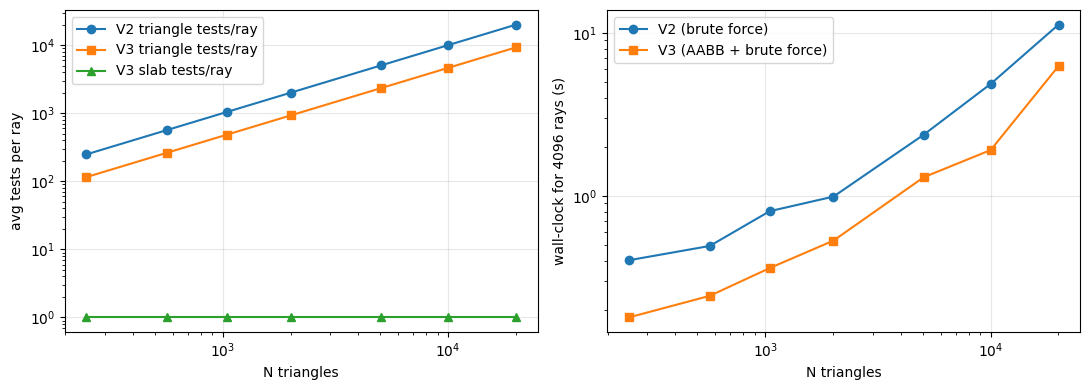

In [9]:
Ns = [200, 500, 1000, 2000, 5000, 10000, 20000]
rows = []
eye, D = camera_rays(64, 64, (0, 1.5, 9), (0, 0, 0), fov=50)
for N in Ns:
    V, F = build_scene(N); box = mesh_aabb(V, F)
    c2, c3 = Counters(), Counters()
    t0 = time.perf_counter(); r2 = [trace_v2(eye, d, V, F, c2)      for d in D]; T2 = time.perf_counter()-t0
    t0 = time.perf_counter(); r3 = [trace_v3(eye, d, V, F, box, c3) for d in D]; T3 = time.perf_counter()-t0
    assert all(a[0]==b[0] for a,b in zip(r2,r3))
    rows.append((len(F), c2.tri/len(D), c3.slab/len(D), c3.tri/len(D), T2, T3))
    print(f"N={len(F):6d} | V2 tri/ray {rows[-1][1]:9.0f} | V3 slab/ray {rows[-1][2]:.0f}, tri/ray {rows[-1][3]:9.0f} | time V2 {T2:6.2f}s  V3 {T3:6.2f}s  speedup x{T2/T3:.2f}")
R = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(R[:,0], R[:,1], 'o-', label="V2 triangle tests/ray"); ax[0].plot(R[:,0], R[:,3], 's-', label="V3 triangle tests/ray")
ax[0].plot(R[:,0], R[:,2], '^-', label="V3 slab tests/ray")
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel("N triangles"); ax[0].set_ylabel("avg tests per ray"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(R[:,0], R[:,4], 'o-', label="V2 (brute force)"); ax[1].plot(R[:,0], R[:,5], 's-', label="V3 (AABB + brute force)")
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].set_xlabel("N triangles"); ax[1].set_ylabel("wall-clock for 4096 rays (s)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Shaded 128×128 render — what the whole-scene box rejects
Left: diffuse render (V3). Right: pixels coloured by what V3 did — **blue = rejected by the AABB (0 triangle tests)**, grey = passed the box test and scanned all N triangles but hit nothing, orange = hit.

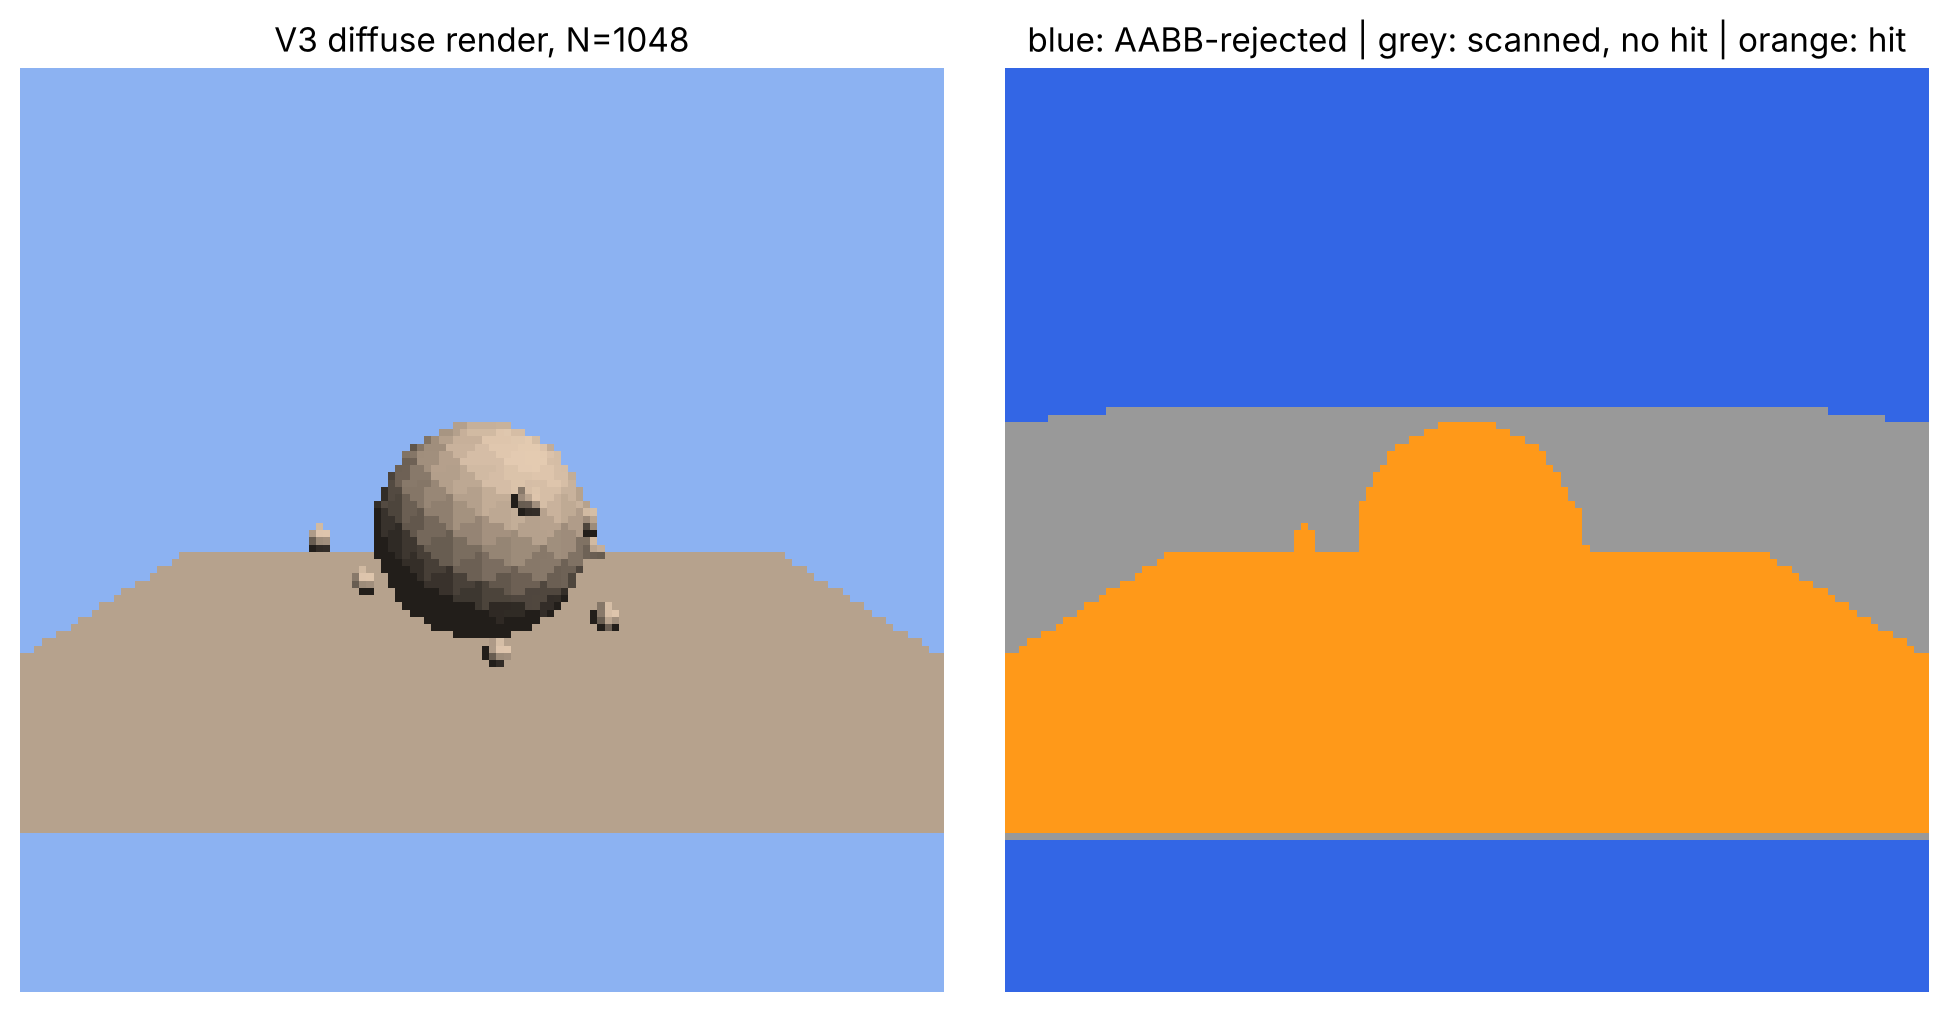

53.4% of the 16,384 rays were rejected by one slab test; render time 1.82s
average triangle tests/ray: V3 = 489  vs  V2 = 1048


In [ ]:
V, F = build_scene(1000); box = mesh_aabb(V, F)
W = H = 128
eye, D = camera_rays(W, H, (0, 1.5, 9), (0, 0, 0), fov=50)
L = np.array([0.5, 1.0, 0.7]); L /= np.linalg.norm(L)
img = np.zeros((H*W, 3)); cls = np.zeros(H*W, int)
cnt = Counters(); t0 = time.perf_counter()
for k, d in enumerate(D):
    box_hit, _, _ = ray_aabb(eye, d, *box)
    i, t = trace_v3(eye, d, V, F, box, cnt)
    if i < 0:
        img[k] = [0.55, 0.7, 0.95]; cls[k] = 0 if not box_hit else 1
    else:
        n = np.cross(V[F[i,1]]-V[F[i,0]], V[F[i,2]]-V[F[i,0]]); n /= np.linalg.norm(n)
        if n @ d > 0: n = -n
        img[k] = np.clip(0.15 + 0.85*max(0, n @ L), 0, 1) * np.array([0.9, 0.8, 0.7]); cls[k] = 2
el = time.perf_counter() - t0
palette = np.array([[0.2,0.4,0.9],[0.6,0.6,0.6],[1.0,0.6,0.1]])
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img.reshape(H, W, 3)); ax[0].set_title(f"V3 diffuse render, N={len(F)}"); ax[0].axis('off')
ax[1].imshow(palette[cls].reshape(H, W, 3)); ax[1].set_title("blue: AABB-rejected | grey: scanned, no hit | orange: hit"); ax[1].axis('off')
plt.tight_layout(); plt.show()
print(f"{(cls==0).mean()*100:.1f}% of the 16,384 rays were rejected by one slab test; render time {el:.2f}s")
print(f"average triangle tests/ray: V3 = {cnt.tri/len(D):.0f}  vs  V2 = {len(F)}")

## 8. Take-aways
* The slab test costs O(1) per ray and **never** changes the answer (V3 ≡ V2 on every ray).
* V3 only helps rays that *miss the whole object*. A ray that enters the box still scans all N triangles → worst case stays Θ(N), which is why Stages 4–5 build a BVH (a *tree* of boxes).
* The speed-up of V3 over V2 equals roughly 1 / (fraction of rays that touch the box). With the camera filling the screen with geometry the gain is small; for a small object in a big frame it is large.